# 01 — The data: synthetic households and the demo

The app forecasts **one household's monthly series by category**, entered by hand. Those
series are short (the maintainer's own history starts in October 2026), monthly, often
intermittent (a repair, a doctor), strongly seasonal for some categories (December, the summer
holidays) and mixed with **fixed expenses** whose future occurrences the app already knows.

No real household's data is used anywhere in this study: `data/` and the app's database are out
of bounds. Instead, `synthetic.py` draws a panel of 200 French households from a fixed seed,
with components we control, and we also load the app's **demo household** (F-ADM-5) exactly as
the app reads it, through `kwak_core.forecast.build_series`.

This notebook describes both and measures the properties that decide which models can work:
series length, intermittency (Syntetos–Boylan ADI and CV²), seasonality strength and the share of
the spending that is fixed.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import study
import synthetic

df, interventions = study.full_panel()
print(f"{df['household'].nunique()} households, {df['unique_id'].nunique()} series, "
      f"{len(df):,} household-category-months, {len(interventions)} with an intervention")
df.head()

200 households, 2600 series, 123,344 household-category-months, 51 with an intervention


,household,category,kind,t,month_of_year,fixed,variable,ds,y,unique_id
0,0,Housing,expense,0,9,940.55,0.0,2022-09-01,940.55,000/Housing
1,0,Housing,expense,1,10,940.55,0.0,2022-10-01,940.55,000/Housing
2,0,Housing,expense,2,11,940.55,0.0,2022-11-01,940.55,000/Housing
3,0,Housing,expense,3,12,940.55,0.0,2022-12-01,940.55,000/Housing
4,0,Housing,expense,4,1,940.55,0.0,2023-01-01,940.55,000/Housing


## How the panel is drawn

Each household gets a size (1 to 4 people), a net income (lognormal around €3,500–4,400), a
housing cost of 22–33 % of it (paid as a fixed expense; owners also pay a property tax in
October, typed by hand), subscriptions, a savings transfer, and for each variable category a
level proportional to income and size, a slow monthly drift, a yearly seasonal profile and
multiplicative lognormal noise whose spread grows in the peak months (heteroscedasticity).
Some categories hold a line only some months (`p_line` below). Structural breaks: a raise
(60 % of households), a car (25 %), a child starting school (half of the larger households),
a rent indexation, a subscription price rise. A 13th month is paid in December by 45 % of
households. About 30 % of households get an **intervention**: from a known month, a category's
level is cut by 8–25 % (a budget target that works), the ground truth of notebook 08.

In [2]:
pd.DataFrame(
    [
        {"category": n, "kind": k, "share of income": s, "seasonal": p is not None,
         "months with a line": pl, "noise σ": sig}
        for n, k, s, p, pl, sig in synthetic.CATEGORIES
    ]
)

,category,kind,share of income,seasonal,months with a line,noise σ
0,Housing,expense,0.000,False,1.00,0.00
1,Groceries,expense,0.150,True,1.00,0.08
2,Transport,expense,0.070,True,1.00,0.18
3,Children,expense,0.040,True,1.00,0.15
4,Health,expense,0.015,False,0.55,0.60
5,Subscriptions,expense,0.000,False,1.00,0.00
6,Home,expense,0.030,True,0.60,0.70
7,Leisure,expense,0.050,True,1.00,0.30
8,Shopping,expense,0.030,True,0.95,0.40
9,Gifts,expense,0.012,True,0.40,0.50


## Lengths

Households have 36 to 60 months (all ending on the same month), like a household that has used
the app for three to five years. The benchmark notebooks cut every household to its **last 48
months** (60 households drawn among those with 48 or more), and a "short history" variant to
30 months tests what happens below two years.

In [3]:
lengths = df.groupby("household")["t"].max() + 1
print(lengths.describe().round(1).to_string())
print("households with ≥ 48 months:", int((lengths >= 48).sum()))

count    200.0
mean      47.4
std        7.4
min       36.0
25%       41.0
50%       47.0
75%       54.0
max       60.0
households with ≥ 48 months: 92


## Fixed and variable

The app forecasts only the **variable** part of each category: the fixed expenses' occurrences
are added as they are known (F-FCT-2). Here is how much of each kind of spending is fixed.

In [4]:
by_cat = df.groupby("category")[["fixed", "variable"]].sum()
by_cat["fixed share"] = by_cat["fixed"] / (by_cat["fixed"] + by_cat["variable"]).abs()
by_cat.round(2).sort_values("fixed share", ascending=False)

,fixed,variable,fixed share
category,,,
Savings,5202301.39,-287264.45,1.06
Subscriptions,948016.76,0.00,1.00
Housing,11251117.47,582004.35,0.95
Gifts,0.00,221889.70,0.00
Children,0.00,1772941.77,0.00
Home,0.00,909245.64,0.00
Health,0.00,413447.59,0.00
Groceries,0.00,6787500.08,0.00
Leisure,0.00,2278879.03,0.00


Housing (bar the property tax), subscriptions and savings transfers are almost entirely fixed:
once their fixed part is removed, there is little or nothing left to forecast. The models' work
is on groceries, transport, leisure, the intermittent categories and the salaries.

## Intermittency: ADI and CV²

Syntetos and Boylan classify a demand series by the **average inter-demand interval** (ADI,
months between two non-empty months) and the **squared coefficient of variation** of the
non-zero amounts (CV²). The cut-offs ADI = 1.32 and CV² = 0.49 split series into *smooth*,
*erratic*, *intermittent* and *lumpy*. Intermittent and lumpy series are where averages and
Croston-type methods (ADIDA, TSB) are expected to beat models built for continuous series.

In [5]:
v = synthetic.variable_series(df)

def adi_cv2(y: pd.Series) -> pd.Series:
    nz = y[y != 0]
    adi = len(y) / max(len(nz), 1)
    cv2 = (nz.std() / nz.mean()) ** 2 if len(nz) > 1 and nz.mean() != 0 else np.nan
    return pd.Series({"ADI": adi, "CV2": cv2})

klass = v.groupby("unique_id")["y"].apply(adi_cv2).unstack()
klass["category"] = klass.index.str.split("/").str[1]
klass["class"] = np.select(
    [(klass.ADI < 1.32) & (klass.CV2 < 0.49), (klass.ADI < 1.32), (klass.CV2 < 0.49)],
    ["smooth", "erratic", "intermittent"], "lumpy",
)
print(klass["class"].value_counts().to_string())
pd.crosstab(klass["category"], klass["class"])

class
smooth          1302
lumpy            456
intermittent     342
erratic          102


class,erratic,intermittent,lumpy,smooth
category,,,,
Children,0,0,0,200
Gifts,0,23,177,0
Groceries,0,0,0,200
Health,0,78,121,1
Home,3,40,157,0
Housing,0,94,0,0
Leisure,47,0,0,153
Miscellaneous,47,0,0,153
Salaries,0,0,0,200


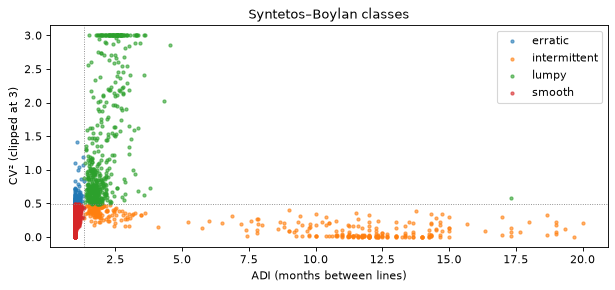

In [6]:
fig, ax = plt.subplots()
for name, g in klass.groupby("class"):
    ax.scatter(g.ADI, g.CV2.clip(upper=3), s=8, label=name, alpha=0.6)
ax.axvline(1.32, color="grey", lw=0.8, ls=":")
ax.axhline(0.49, color="grey", lw=0.8, ls=":")
ax.set(xlabel="ADI (months between lines)", ylabel="CV² (clipped at 3)", title="Syntetos–Boylan classes")
ax.legend()
plt.show()

## Seasonality strength

Following Wang, Smith and Hyndman, the strength of the yearly seasonality is
$F_s = \max(0, 1 - \mathrm{Var}(R)/\mathrm{Var}(S+R))$ from an STL decomposition (period 12):
0 means none, 1 a pure seasonal pattern. Seasonal models (seasonal naive, seasonal ETS/Theta)
can only pay off where it is high, and they need at least two full years to learn it.

In [7]:
from statsmodels.tsa.seasonal import STL

def strength(y: np.ndarray) -> float:
    if len(y) < 36 or np.allclose(y, y[0]):
        return np.nan
    r = STL(y, period=12, robust=True).fit()
    return max(0.0, 1 - np.var(r.resid) / np.var(r.seasonal + r.resid))

sample = v[v["unique_id"].isin(v["unique_id"].drop_duplicates().sample(400, random_state=0))]
fs = sample.groupby("unique_id")["y"].apply(lambda s: strength(s.to_numpy(float)))
fs = fs.to_frame("Fs").assign(category=lambda d: d.index.str.split("/").str[1])
fs.groupby("category")["Fs"].median().round(2).sort_values(ascending=False)

category
Housing          0.99
Children         0.83
Leisure          0.76
Groceries        0.65
Transport        0.45
Salaries         0.44
Shopping         0.38
Health           0.31
Miscellaneous    0.30
Gifts            0.21
Home             0.18
Savings          0.00
Name: Fs, dtype: float64

Housing's variable part (the property tax typed by hand each October) is almost purely
seasonal; children (back to school), leisure (the summer holidays) and groceries carry a clear
yearly pattern; transport and salaries (a 13th month in 45 % of households) a moderate one;
health, home and miscellaneous little beyond noise. Gifts score low **despite** their December
peak: they are lumpy, and the robust STL treats isolated spikes as remainder. A strength
measure is itself fragile on short intermittent series. (400 series sampled for speed.)

## A few series

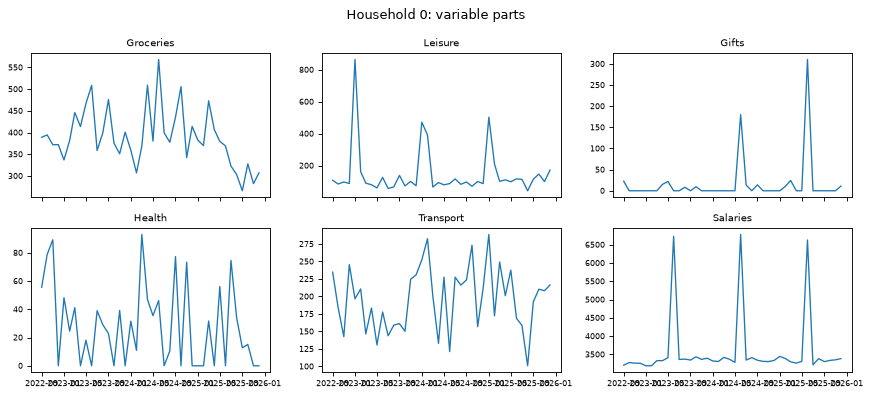

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True)
h0 = v["household"].iloc[0]
for ax, cat in zip(axes.flat, ["Groceries", "Leisure", "Gifts", "Health", "Transport", "Salaries"]):
    g = v[(v.household == h0) & (v.category == cat)]
    ax.plot(g.ds, g.y, lw=1.2)
    ax.set_title(cat, fontsize=9)
    ax.tick_params(labelsize=7)
fig.suptitle(f"Household {h0}: variable parts")
plt.tight_layout()
plt.show()

## The app's demo household

The demo (three years, a couple with a child) is generated by `kwak_core.demo.generate` and
turned into series by `kwak_core.forecast.build_series`, the same code the app runs: lines
created from a fixed expense, or typed with its label in a month its schedule falls in, are
**fixed**; everything else is variable.

In [9]:
demo = synthetic.demo_household()
summary = demo.groupby(["category", "kind"])[["y", "fixed", "variable"]].sum().round(0)
summary["fixed share"] = (summary["fixed"] / summary["y"].abs()).round(2)
summary.sort_values("y", ascending=False)

,,y,fixed,variable,fixed share
category,kind,,,,
Salaries,income,197880.0,0.0,197880.0,0.00
Housing,expense,48720.0,48720.0,0.0,1.00
Savings,savings,29600.0,33100.0,-3500.0,1.12
Transport,expense,24198.0,9072.0,15126.0,0.37
Groceries,expense,22339.0,0.0,22339.0,0.00
Children,expense,17575.0,16120.0,1455.0,0.92
Leisure,expense,15069.0,1152.0,13917.0,0.08
Benefits,income,11376.0,0.0,11376.0,0.00
Home,expense,6342.0,3528.0,2814.0,0.56


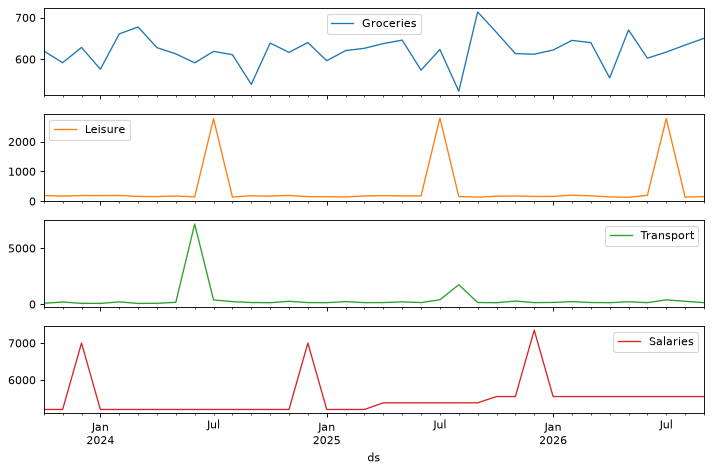

In [10]:
piv = demo.pivot_table(index="ds", columns="category", values="variable")
piv[["Groceries", "Leisure", "Transport", "Salaries"]].plot(subplots=True, figsize=(9, 6), lw=1.2)
plt.tight_layout()
plt.show()

**What this means for the study**

- Series are **short** (36–60 months, and the real household's will be shorter for years):
  every model must be judged on rolling origins with honest training lengths, and anything that
  needs long histories (seasonal models, ML with 12-month lags, deep nets) starts handicapped.
- Many series are **intermittent or lumpy**: scaled errors (MASE) and Croston-family methods are
  needed; percentage errors (MAPE) are undefined on empty months.
- A large part of the spending is **fixed** and known: removing it before modelling is the
  single biggest simplification the app makes.
- Seasonality is **strong but category-specific**: a per-series model choice is warranted.